# Лабораторная работа № 1
## Многомерная оптимизация функции генетическим алгоритмом

### Вариант

$N = 10,\ Q = 0,\ Y = 26$

$$V = 1 + ((17N + 7Q + Y) \bmod 20) = 1 + (196 \bmod 20) = 17$$

$$d = 5 + (V \bmod 6) = 10$$

Функция: Sum of Different Powers

### Постановка

$$
\mathbf{x}^* = \arg\min_{\mathbf{x} \in D} f(\mathbf{x}), \qquad
f(\mathbf{x}) = \sum_{i=1}^{d} |x_i|^{\,i+1}, \qquad
D = [-1, 1]^{10}
$$

* Оптимум: $\mathbf{x}^* = \mathbf{0}$, $f^* = 0$
* Ограничения: только границы $-1 \le x_i \le 1$

### Представление особи

* Генотип: $\mathbf{x} \in \mathbb{R}^{10}$ (вещественное кодирование)
* Фенотип: $\mathbf{x}$ (декодирование не нужно)
* Фитнес: $f(\mathbf{x}) \to \min$

## 1. Функции

* Все эволюционные операторы написаны вручную
* Библиотеки: `numpy` (ГПСЧ, массивы), `pandas` (таблицы), `matplotlib` (графики)

In [1]:
import time
from dataclasses import dataclass, asdict, replace
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)

D = 10                 # размерность варианта
LOW, HIGH = -1.0, 1.0  # границы области поиска

plt.rcParams.update({"figure.figsize": (9, 5), "axes.grid": True, "grid.alpha": 0.3})

### 1.1. Целевая функция

* `sum_diff_powers(X)`: $X \in \mathbb{R}^{n \times d} \mapsto \big(f(X_1), \dots, f(X_n)\big)$
* `Objective` — счётчик вычислений $f$ (бюджет считается в вычислениях $f$)

In [2]:
def sum_diff_powers(X):
    """f(x) = sum_i |x_i|^(i+1), i = 1..d. X: (n, d) или (d,)."""
    X = np.atleast_2d(X)
    powers = np.arange(2, X.shape[1] + 2)
    return np.sum(np.abs(X) ** powers, axis=1)


class Objective:
    """Обёртка над функцией со счётчиком вычислений."""

    def __init__(self, func):
        self.func = func
        self.evals = 0

    def __call__(self, X):
        X = np.atleast_2d(X)
        self.evals += X.shape[0]
        return self.func(X)

### 1.2. Инициализация и границы

* Инициализация: $x_i \sim U[l, u]$
* Отражение от границы, $D = [l, u]^d$:

$$
x' = \begin{cases} 2l - x, & x < l \\ x, & l \le x \le u \\ 2u - x, & x > u \end{cases}
$$

In [3]:
def init_population(rng, n, d, low, high):
    return rng.uniform(low, high, size=(n, d))


def repair_bounds(X, low, high):
    width = high - low
    # отражение с периодом 2*width: корректно и для сильных выходов за границу
    Y = np.mod(X - low, 2 * width)
    Y = np.where(Y > width, 2 * width - Y, Y)
    return low + Y

### 1.3. Селекция — турнирная

$T$ — $k = 3$ случайных особи:

$$i^* = \arg\min_{j \in T} f_j$$

In [4]:
def select_tournament(rng, fit, n_select, k=3):
    idx = rng.integers(0, len(fit), size=(n_select, k))
    winners = np.argmin(fit[idx], axis=1)
    return idx[np.arange(n_select), winners]

### 1.4. Кроссовер — равномерный

Применяется к паре с вероятностью $p_c$, для каждого гена:

$$
(c^1_i,\ c^2_i) = \begin{cases} (p^1_i,\ p^2_i), & u_i < 0.5 \\ (p^2_i,\ p^1_i), & u_i \ge 0.5 \end{cases}, \qquad u_i \sim U[0, 1]
$$

In [5]:
def crossover_uniform(rng, P1, P2):
    mask = rng.random(P1.shape) < 0.5
    return np.where(mask, P1, P2), np.where(mask, P2, P1)

### 1.5. Мутация — гауссовская

Каждый ген с вероятностью $p_m = 1/d$:

$$x_i' = x_i + \sigma\, \mathcal{N}(0, 1), \qquad \sigma = \sigma_0 (u - l)$$

In [6]:
def mutate_gaussian(rng, X, sigma, pm):
    mask = rng.random(X.shape) < pm
    return X + mask * rng.normal(0.0, sigma, X.shape)

### 1.6. ГА

```
P(0) ~ U(D),  оценка f
   │
   ▼
┌─► evals + (μ−e) > бюджет ? ──да──► вернуть x_best
│      │ нет
│      ▼
│   турнирная селекция родителей
│      ▼
│   равномерный кроссовер пар (p_c)
│      ▼
│   гауссовская мутация (p_m, sigma)
│      ▼
│   отражение от границ, оценка f
│      ▼
│   P(t+1) = e лучших из P(t) ∪ (μ−e) потомков
└──────┘
```

* Элитизм: $e = 2$
* Остановка: бюджет вычислений $f$
* Все параметры — в `GAConfig`

In [7]:
@dataclass
class GAConfig:
    pop_size: int = 50          # μ — размер популяции
    max_evals: int = 10_000     # бюджет вычислений f
    tournament_k: int = 3
    pc: float = 0.9             # вероятность кроссовера для пары
    pm: float = 0.1             # вероятность мутации гена (= 1/d)
    sigma0: float = 0.01        # масштаб мутации, доля ширины области
    elite: int = 2              # число элитных особей


def run_ga(cfg: GAConfig, seed: int, func=sum_diff_powers, d=D, low=LOW, high=HIGH):
    """Один запуск ГА. Возвращает лучшее решение и историю по поколениям."""
    rng = np.random.default_rng(seed)
    obj = Objective(func)
    mu, e = cfg.pop_size, cfg.elite
    n_off = mu - e
    n_pairs = (n_off + 1) // 2
    sigma = cfg.sigma0 * (high - low)

    pop = init_population(rng, mu, d, low, high)
    fit = obj(pop)
    best_i = np.argmin(fit)
    best_x, best_f = pop[best_i].copy(), fit[best_i]
    hist = [(obj.evals, best_f)]

    while obj.evals + n_off <= cfg.max_evals:
        # 1. селекция
        par = select_tournament(rng, fit, 2 * n_pairs, k=cfg.tournament_k)
        P1, P2 = pop[par[:n_pairs]], pop[par[n_pairs:]]
        # 2. кроссовер (пары, не прошедшие по p_c, копируются без изменений)
        C1, C2 = crossover_uniform(rng, P1, P2)
        do_cx = (rng.random(n_pairs) < cfg.pc)[:, None]
        C1, C2 = np.where(do_cx, C1, P1), np.where(do_cx, C2, P2)
        child = np.vstack([C1, C2])[:n_off]
        # 3. мутация
        child = mutate_gaussian(rng, child, sigma, cfg.pm)
        # 4. обработка границ и оценка
        child = repair_bounds(child, low, high)
        f_child = obj(child)
        # 5. элитизм: e лучших родителей переходят в следующее поколение
        elite_idx = np.argsort(fit)[:e]
        pop = np.vstack([pop[elite_idx], child])
        fit = np.concatenate([fit[elite_idx], f_child])
        i = np.argmin(fit)
        if fit[i] < best_f:
            best_x, best_f = pop[i].copy(), fit[i]
        hist.append((obj.evals, best_f))

    history = pd.DataFrame(hist, columns=["evals", "best"])
    return {"best_x": best_x, "best_f": best_f, "evals": obj.evals, "history": history}

### 1.7. Случайный поиск

$$\mathbf{x}_t \sim U(D), \qquad f_{\text{best}}(t) = \min_{s \le t} f(\mathbf{x}_s)$$

* Тот же бюджет; история — в тех же точках `evals`, что у ГА

In [8]:
def run_random_search(max_evals, seed, checkpoints, func=sum_diff_powers, d=D, low=LOW, high=HIGH):
    rng = np.random.default_rng(seed)
    obj = Objective(func)
    fvals = obj(rng.uniform(low, high, size=(max_evals, d)))
    best_curve = np.minimum.accumulate(fvals)
    history = pd.DataFrame({"evals": checkpoints, "best": best_curve[np.asarray(checkpoints) - 1]})
    return {"best_f": fvals.min(), "evals": obj.evals, "history": history}

### 1.8. Серии запусков, статистика, график

* `run_series`: seed $= 1000 + r$, $\ r = 0, \dots, R-1$
* `summarize`: $\min,\ \bar f,\ \operatorname{med},\ s,\ \max$ итогового $f$ по серии, время
* `plot_convergence`: среднее лучшего $f$ по серии для нескольких методов на одном графике, лог-шкала

In [9]:
def run_series(runner, n_runs=30, base_seed=1000):
    """runner(seed) -> dict. Возвращает таблицу итогов и список историй."""
    rows, histories = [], []
    for r in range(n_runs):
        seed = base_seed + r
        t0 = time.perf_counter()
        res = runner(seed)
        rows.append({"seed": seed, "best_f": res["best_f"], "evals": res["evals"],
                     "time_s": time.perf_counter() - t0})
        histories.append(res["history"])
    return pd.DataFrame(rows), histories


def summarize(runs: pd.DataFrame, name=""):
    f = runs["best_f"]
    return pd.Series({"best": f.min(), "mean": f.mean(), "median": f.median(), "std": f.std(),
                      "worst": f.max(), "evals": runs["evals"].mean(),
                      "time_s": runs["time_s"].mean()}, name=name)


def plot_convergence(series: dict, title, ax=None):
    """series: {label: histories}. Для каждой серии — среднее лучшего f по запускам."""
    if ax is None:
        _, ax = plt.subplots()
    for label, histories in series.items():
        M = np.vstack([h["best"].to_numpy() for h in histories])
        x = histories[0]["evals"].to_numpy()
        ax.plot(x, M.mean(axis=0), label=label)
    ax.set_yscale("log")
    ax.set_xlabel("число вычислений f")
    ax.set_ylabel("лучшее найденное f (log)")
    ax.set_title(title)
    ax.legend()
    return ax

### 1.9. Проверки

* $f(\mathbf{0}) = 0$, $\ f(\mathbf{1}) = d$, $\ f(0.5, 0.5) = 0.375$
* отражение: результат $\in D$, $\ 1.2 \mapsto 0.8$, $\ -1.3 \mapsto -0.7$
* селекция: $\overline{f}_{\text{выбранных}} < \overline{f}_{\text{популяции}}$
* кроссовер: потомки состоят из генов родителей
* одинаковый seed → одинаковый результат

In [10]:
assert sum_diff_powers(np.zeros(D))[0] == 0.0
assert np.isclose(sum_diff_powers(np.ones(D))[0], D)
assert np.isclose(sum_diff_powers(np.array([0.5, 0.5]))[0], 0.25 + 0.125)

_rng = np.random.default_rng(0)
_R = repair_bounds(_rng.uniform(-5, 5, size=(1000, D)), LOW, HIGH)
assert _R.min() >= LOW and _R.max() <= HIGH
assert np.allclose(repair_bounds(np.array([[1.2, -1.3, 0.4]]), LOW, HIGH), [[0.8, -0.7, 0.4]])

_fit = sum_diff_powers(_R)
assert _fit[select_tournament(_rng, _fit, 5000)].mean() < _fit.mean()

_c1, _c2 = crossover_uniform(_rng, _R[:10], _R[10:20])
assert np.all((_c1 == _R[:10]) | (_c1 == _R[10:20])) and np.allclose(_c1 + _c2, _R[:10] + _R[10:20])

_a = run_ga(GAConfig(max_evals=2000), seed=42)
_b = run_ga(GAConfig(max_evals=2000), seed=42)
assert _a["best_f"] == _b["best_f"] and _a["evals"] <= 2000
print("Все проверки пройдены. Пробный запуск ГА (2000 вычислений): f =", _a["best_f"])

Все проверки пройдены. Пробный запуск ГА (2000 вычислений): f = 2.7816115587355977e-06


## 2. Эксперименты

### 2.1. Параметры

* Бюджет: $10\,000 = 1000 \cdot d$ вычислений $f$
* Запусков: $R = 30$, seed $1000 \dots 1029$
* $\mu = 50$, $e = 2$, $k = 3$, $p_c = 0.9$, $p_m = 1/d = 0.1$, $\sigma_0 = 0.01$

In [11]:
N_RUNS = 30
BASE_SEED = 1000
BASE = GAConfig()

params = pd.Series(asdict(BASE), name="значение").to_frame()
params.loc["n_runs"] = N_RUNS
params.loc["seeds"] = f"{BASE_SEED}..{BASE_SEED + N_RUNS - 1}"
params.to_csv(RESULTS / "base_config.csv")
params

,значение
pop_size,50.0
max_evals,10000.0
tournament_k,3.0
pc,0.9
pm,0.1
sigma0,0.01
elite,2.0
n_runs,30.0
seeds,1000..1029


### 2.2. ГА, 30 запусков

In [12]:
ga_runs, ga_hist = run_series(lambda s: run_ga(BASE, s), N_RUNS, BASE_SEED)
ga_runs.to_csv(RESULTS / "runs_ga.csv", index=False)
summarize(ga_runs, "ГА").to_frame().T

,best,mean,median,std,worst,evals,time_s
ГА,3.678558e-12,1.283966e-09,3.093547e-10,2.245202e-09,1.065228e-08,9986.0,0.009394


Лучшее решение (воспроизводится по seed):

In [13]:
best_seed = int(ga_runs.loc[ga_runs.best_f.idxmin(), "seed"])
best_res = run_ga(BASE, best_seed)
print(f"seed = {best_seed}, f = {best_res['best_f']:.3e}")
pd.DataFrame({"x_i": best_res["best_x"], "|x_i|^(i+1)": np.abs(best_res["best_x"]) ** np.arange(2, D + 2)},
             index=[f"x{i}" for i in range(1, D + 1)])

seed = 1006, f = 3.679e-12


,x_i,|x_i|^(i+1)
x1,-0.000001,1.385606e-12
x2,-0.000132,2.292946e-12
x3,-0.000002,1.214197e-23
x4,0.000366,6.532893e-18
x5,-0.000267,3.592199e-22
x6,-0.000412,1.999214e-24
x7,-0.000190,1.666414e-30
x8,-0.000630,1.570912e-29
x9,0.001462,4.457313e-29
x10,0.002696,5.466559e-29


### 2.3. Сходимость: минимум, среднее, максимум по серии

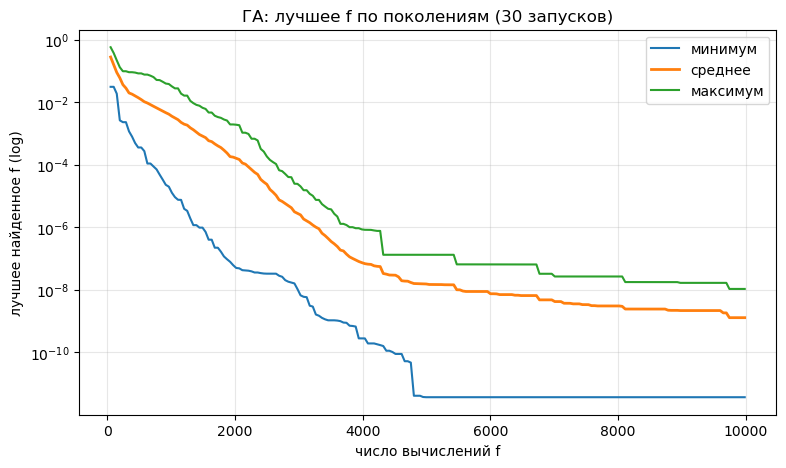

In [14]:
M = np.vstack([h["best"].to_numpy() for h in ga_hist])
x = ga_hist[0]["evals"].to_numpy()
fig, ax = plt.subplots()
ax.plot(x, M.min(axis=0), label="минимум")
ax.plot(x, M.mean(axis=0), label="среднее", lw=2)
ax.plot(x, M.max(axis=0), label="максимум")
ax.set_yscale("log")
ax.set_xlabel("число вычислений f")
ax.set_ylabel("лучшее найденное f (log)")
ax.set_title(f"ГА: лучшее f по поколениям ({N_RUNS} запусков)")
ax.legend()
fig.savefig(RESULTS / "convergence_ga.png", dpi=120, bbox_inches="tight")
plt.show()

### 2.4. Сравнение со случайным поиском

* Тот же бюджет $10^4$, те же seed

,best,mean,median,std,worst,evals,time_s
ГА,3.68e-12,1.28e-09,3.09e-10,2.25e-09,1.07e-08,9986.000000,0.009394
случайный поиск,3.90e-03,1.96e-02,1.92e-02,1.05e-02,5.04e-02,10000.000000,0.001495


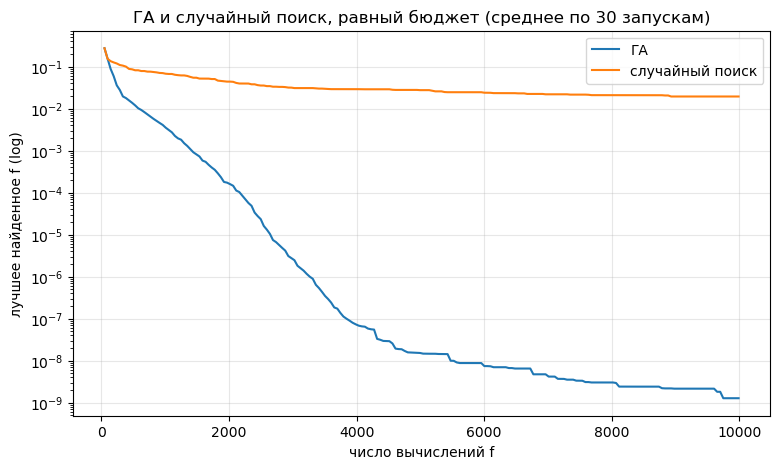

In [15]:
rs_runs, rs_hist = run_series(lambda s: run_random_search(BASE.max_evals, s, x), N_RUNS, BASE_SEED)
rs_runs.to_csv(RESULTS / "runs_random_search.csv", index=False)

cmp_table = pd.DataFrame([summarize(ga_runs, "ГА"), summarize(rs_runs, "случайный поиск")])
cmp_table.to_csv(RESULTS / "summary_ga_vs_random.csv")
display(cmp_table.style.format("{:.2e}", subset=["best", "mean", "median", "std", "worst"]))

fig, ax = plt.subplots()
plot_convergence({"ГА": ga_hist, "случайный поиск": rs_hist}, "ГА и случайный поиск, равный бюджет (среднее по 30 запускам)", ax=ax)
fig.savefig(RESULTS / "convergence_ga_vs_random.png", dpi=120, bbox_inches="tight")
plt.show()

### 2.5. Влияние масштаба мутации $\sigma_0$

* Меняется только $\sigma_0 \in \{0.1,\ 0.01,\ 0.001\}$, остальное как в базе

,best,mean,median,std,worst,evals,time_s
σ0 = 0.1,1.81e-09,4.77e-07,5.57e-08,1.18e-06,6.46e-06,9986.000000,0.009538
σ0 = 0.01,3.68e-12,1.28e-09,3.09e-10,2.25e-09,1.07e-08,9986.000000,0.009363
σ0 = 0.001,3.40e-08,9.48e-04,4.25e-05,2.62e-03,1.25e-02,9986.000000,0.009415


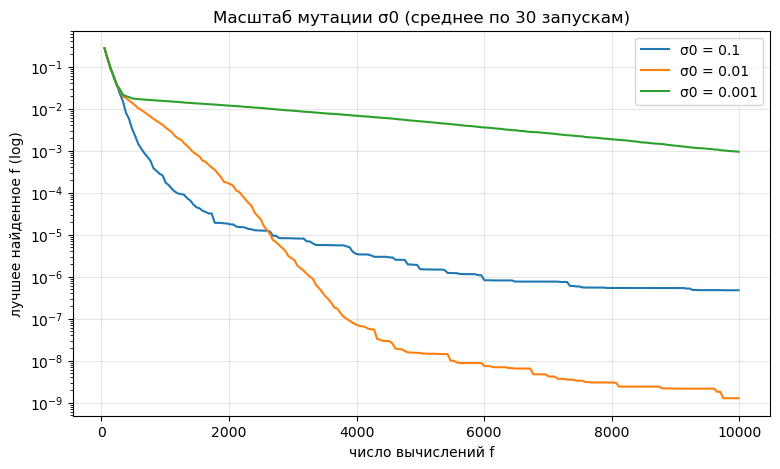

In [16]:
sigma_runs, sigma_hist = {}, {}
for s0 in [0.1, 0.01, 0.001]:
    cfg = replace(BASE, sigma0=s0)
    runs, hist = run_series(lambda s: run_ga(cfg, s), N_RUNS, BASE_SEED)
    runs.to_csv(RESULTS / f"runs_sigma_{s0}.csv", index=False)
    sigma_runs[f"σ0 = {s0}"], sigma_hist[f"σ0 = {s0}"] = runs, hist

sigma_table = pd.DataFrame([summarize(r, k) for k, r in sigma_runs.items()])
sigma_table.to_csv(RESULTS / "summary_sigma.csv")
display(sigma_table.style.format("{:.2e}", subset=["best", "mean", "median", "std", "worst"]))

fig, ax = plt.subplots()
plot_convergence(sigma_hist, "Масштаб мутации σ0 (среднее по 30 запускам)", ax=ax)
fig.savefig(RESULTS / "convergence_sigma.png", dpi=120, bbox_inches="tight")
plt.show()

## 3. Почему функция трудна для случайного и локального поиска

$f$ выпукла и унимодальна, трудность — **разная чувствительность координат**:

1. Порог точности по координате: $|x_i|^{i+1} < \varepsilon \iff |x_i| < \varepsilon^{1/(i+1)}$

| $\varepsilon = 10^{-8}$ | $x_1$ | $x_2$ | $x_5$ | $x_{10}$ |
|---|---|---|---|---|
| $\varepsilon^{1/(i+1)}$ | $10^{-4}$ | $2 \cdot 10^{-3}$ | $0.046$ | $0.19$ |

$\quad$ → один шаг не подходит всем координатам

2. Плато: $\dfrac{\partial f}{\partial x_i} = (i+1)\,|x_i|^{i}\operatorname{sign}x_i \approx 0$ при больших $i$ → направление к оптимуму почти не видно
3. Случайный поиск: $\ \mathbb{P}(f < \varepsilon) \le \mathbb{P}(|x_1| < \sqrt{\varepsilon}) = 10^{-4}$ на одну пробу, и это только по $x_1$
4. Локальный поиск с фиксированным шагом $h$: большой $h$ → не может уточнить $x_1$, малый $h$ → долго идёт к оптимуму
   (то же видно в 2.5 для $\sigma_0$)

## 4. Выводы

### 4.1. Результаты ($R = 30$, бюджет $10^4$)

| метод | best | median | worst |
|---|---|---|---|
| ГА, $\sigma_0 = 0.01$ | 3.7e-12 | 3.1e-10 | 1.1e-08 |
| случайный поиск | 3.9e-03 | 1.9e-02 | 5.0e-02 |
| ГА, $\sigma_0 = 0.1$ | 1.8e-09 | 5.6e-08 | 6.5e-06 |
| ГА, $\sigma_0 = 0.001$ | 3.4e-08 | 4.3e-05 | 1.3e-02 |

1. **ГА лучше случайного поиска на $\sim 8$ порядков** по медиане; худший запуск ГА ($10^{-8}$) лучше лучшего запуска случайного поиска ($4 \cdot 10^{-3}$)
2. **Масштаб мутации — компромисс:**
   * $\sigma_0 = 0.1$ — быстрый старт, но шаг $\gg 10^{-4}$ → $x_1$ не уточняется, медиана $6 \cdot 10^{-8}$
   * $\sigma_0 = 0.001$ — шаг мал, до оптимума от $|x_i| \sim 0.5$ далеко → медленно, медиана $4 \cdot 10^{-5}$
   * $\sigma_0 = 0.01$ — лучший из трёх

### 4.2. Почему результат хороший

* $f^* = 0$ известен → ошибка равна $f$
* Медиана $3 \cdot 10^{-10}$, худший запуск $1.1 \cdot 10^{-8}$ из 30 → результат устойчив, а не единичный удачный запуск
* Лучшее решение: $|x_1| \sim 10^{-6}$, $|x_{10}| \sim 3 \cdot 10^{-3}$ — все координаты близки к нулю
* **Ограничение:** $f$ выпукла, поэтому градиентный метод тоже бы справился; ГА здесь — учебный пример